# 4-panel correlations

Top row: DeepSeek (English, Italian). Bottom row: LLaMA (English, Italian).

/tmp/ipykernel_2518725/1082892753.py:115: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.savefig(figs_dir / '4-panel-corrs.pdf', dpi=200, bbox_inches='tight')
/home/acevedo/venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


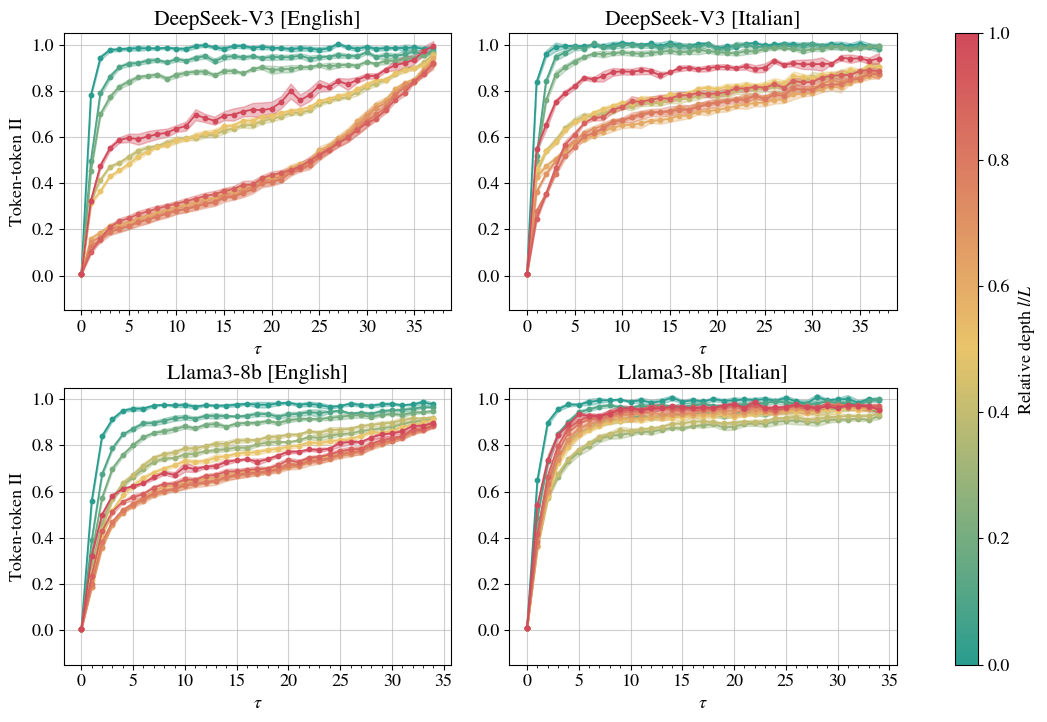

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from cycler import cycler

# Style
rcpsize = 13
plt.rcParams['xtick.labelsize'] = rcpsize
plt.rcParams['ytick.labelsize'] = rcpsize
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['font.size'] = rcpsize
plt.rcParams.update({'figure.autolayout': True})
base_colors = plt.style.library['seaborn-v0_8-dark-palette']['axes.prop_cycle'].by_key()['color']
plt.rcParams['axes.prop_cycle'] = cycler(color=base_colors)

figs_dir = Path('results/figs')
figs_dir.mkdir(parents=True, exist_ok=True)

depth_cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list(
    'depth3', ['#2A9D8F', '#E9C46A', '#D1495B'], N=256
)
depth_norm = plt.Normalize(vmin=0.0, vmax=1.0)

def ab_path(model, language, seed, n_files, min_token_length, mask=2, k=10, nbits=0):
    return Path('results/santiago') / (
        'subtract_mean_0'
    ) / (
        'batch_shuffle_0'
    ) / (
        'take_last_1'
    ) / (
        f'modelA_{model}'
    ) / (
        f'modelB_{model}'
    ) / (
        f'n_files_{n_files}'
    ) / (
        f'min_token_length_{min_token_length}'
    ) / (
        f'languageA_{language}'
    ) / (
        f'mask_{mask}'
    ) / (
        f'k_{k}'
    ) / (
        f'Nbits_{nbits}'
    ) / (
        f'seed_{seed}'
    ) / 'n_tokens_1_avg_0_AB.npy'

def load_ab(model, language, n_files, min_token_length, seeds=(0, 1, 2, 3, 4)):
    arrays = []
    for seed in seeds:
        p = ab_path(model=model, language=language, seed=seed, n_files=n_files, min_token_length=min_token_length)
        if not p.exists():
            raise FileNotFoundError(p)
        arrays.append(np.load(p))
    return np.stack(arrays, axis=0)  # [seed, layer, tau]

def plot_corr_panel(ax, ab_seed_layer_tau, title, relative_depths):
    n_layers = ab_seed_layer_tau.shape[1]
    n_tau = ab_seed_layer_tau.shape[2]
    x = np.arange(n_tau)

    layer_ids = np.clip((relative_depths * n_layers).astype(int), 0, n_layers - 1)
    depth_colors = depth_cmap(depth_norm(relative_depths))

    for i, layer_id in enumerate(layer_ids):
        mu = ab_seed_layer_tau[:, layer_id, :].mean(axis=0)
        std = ab_seed_layer_tau[:, layer_id, :].std(axis=0)
        ax.plot(x, mu, linestyle='-', marker='o', ms=3.2, lw=1.3, color=depth_colors[i])
        ax.fill_between(x, mu - std, mu + std, alpha=0.35, color=depth_colors[i])

    ax.grid(which='major', alpha=0.6)
    ax.set_xlabel(r'$\tau$')
    ax.set_title(title)
    ax.set_xticks(np.arange(0, n_tau + 1, 5))
    ax.set_xticks(np.arange(0, n_tau + 1, 1), minor=True)
    ax.set_ylim(-0.15, 1.05)

# Data
deepseek_rel_depths = np.array([0.001, 0.1, 0.2, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.999])
llama_rel_depths = np.array([0.001, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.999])

ab_ds_en = load_ab(model='deepseek', language='english', n_files=400, min_token_length=40)
ab_ds_it = load_ab(model='deepseek', language='italian', n_files=400, min_token_length=40)
ab_ll_en = load_ab(model='llama', language='english', n_files=400, min_token_length=37)
ab_ll_it = load_ab(model='llama', language='italian', n_files=400, min_token_length=37)

fig = plt.figure(figsize=(11.8, 8.2))
gs = fig.add_gridspec(2, 3, width_ratios=[1, 1, 0.06], hspace=0.28, wspace=0.22)
ax00 = fig.add_subplot(gs[0, 0])
ax01 = fig.add_subplot(gs[0, 1], sharey=ax00)
ax10 = fig.add_subplot(gs[1, 0], sharey=ax00)
ax11 = fig.add_subplot(gs[1, 1], sharey=ax00)
cax = fig.add_subplot(gs[:, 2])

plot_corr_panel(ax00, ab_ds_en, 'DeepSeek-V3 [English]', deepseek_rel_depths)
plot_corr_panel(ax01, ab_ds_it, 'DeepSeek-V3 [Italian]', deepseek_rel_depths)
plot_corr_panel(ax10, ab_ll_en, 'Llama3-8b [English]', llama_rel_depths)
plot_corr_panel(ax11, ab_ll_it, 'Llama3-8b [Italian]', llama_rel_depths)

ax00.set_ylabel('Token-token II')
ax10.set_ylabel('Token-token II')

sm = plt.cm.ScalarMappable(cmap=depth_cmap, norm=depth_norm)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cax)
cbar.set_label(r'Relative depth $l/L$')
ticks = np.round(np.linspace(0.0, 1.0, 6), 2)
cbar.set_ticks(ticks)
cbar.set_ticklabels([f'{t:.1f}' for t in ticks])

fig.savefig(figs_dir / '4-panel-corrs.pdf', dpi=200, bbox_inches='tight')
plt.show()


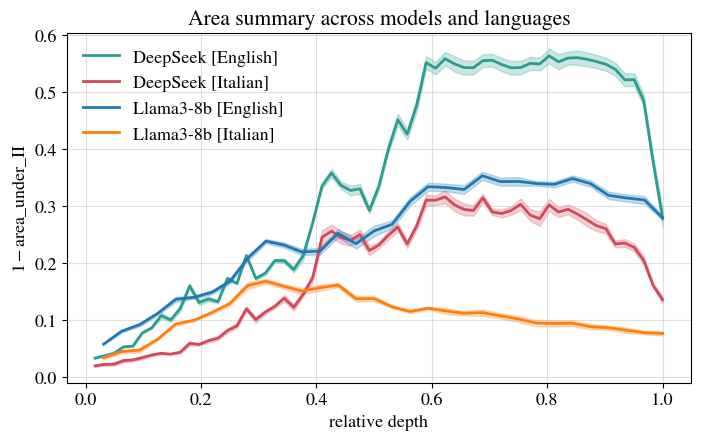

In [2]:
# Area summary: 1 - area_under_II for both models and languages
def one_minus_area_stats(ab_seed_layer_tau):
    n_tau = ab_seed_layer_tau.shape[-1]
    x_tau = np.arange(n_tau)
    area = np.trapezoid(ab_seed_layer_tau, x=x_tau, axis=-1) / (n_tau - 1)
    one_minus_area = 1.0 - area  # [seed, layer]
    mu = one_minus_area.mean(axis=0)
    std = one_minus_area.std(axis=0)
    rel_depth = np.arange(1, one_minus_area.shape[1] + 1) / one_minus_area.shape[1]
    return rel_depth, mu, std

series = [
    ('DeepSeek [English]', ab_ds_en, '#2A9D8F'),
    ('DeepSeek [Italian]', ab_ds_it, '#D1495B'),
    ('Llama3-8b [English]', ab_ll_en, '#1f77b4'),
    ('Llama3-8b [Italian]', ab_ll_it, '#ff7f0e'),
]

fig, ax = plt.subplots(1, 1, figsize=(7.2, 4.6))
for label, ab_data, color in series:
    x, mu, std = one_minus_area_stats(ab_data)
    ax.plot(x, mu, color=color, lw=2.0, label=label)
    ax.fill_between(x, mu - std, mu + std, color=color, alpha=0.25)

ax.set_xlabel('relative depth')
ax.set_ylabel(r'$1-\mathrm{area\_under\_II}$')
ax.set_title('Area summary across models and languages')
ax.grid(alpha=0.4)
ax.legend(frameon=False, ncol=1)

fig.savefig(figs_dir / '4-panel-corrs_area-summary.pdf', dpi=200, bbox_inches='tight')
plt.show()


/tmp/ipykernel_2518725/3987122140.py:25: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.savefig(figs_dir / '4-panel-corrs_single-row.pdf', dpi=200, bbox_inches='tight')
/home/acevedo/venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


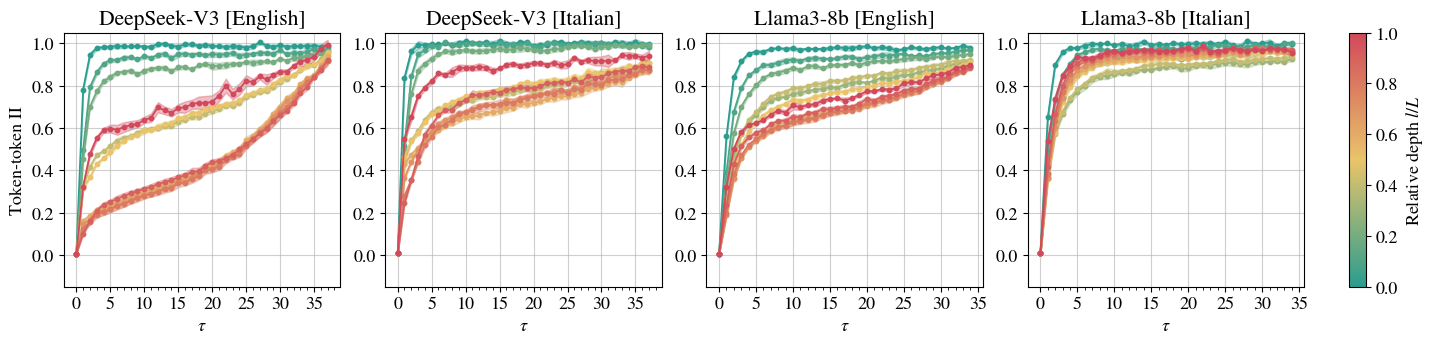

In [6]:
# Same correlations in one row: DeepSeek EN, DeepSeek IT, LLaMA EN, LLaMA IT
fig = plt.figure(figsize=(16.8, 3.3))
gs = fig.add_gridspec(1, 5, width_ratios=[1, 1, 1, 1, 0.06], wspace=0.20)
ax0 = fig.add_subplot(gs[0, 0])
ax1 = fig.add_subplot(gs[0, 1], sharey=ax0)
ax2 = fig.add_subplot(gs[0, 2], sharey=ax0)
ax3 = fig.add_subplot(gs[0, 3], sharey=ax0)
cax = fig.add_subplot(gs[0, 4])

plot_corr_panel(ax0, ab_ds_en, 'DeepSeek-V3 [English]', deepseek_rel_depths)
plot_corr_panel(ax1, ab_ds_it, 'DeepSeek-V3 [Italian]', deepseek_rel_depths)
plot_corr_panel(ax2, ab_ll_en, 'Llama3-8b [English]', llama_rel_depths)
plot_corr_panel(ax3, ab_ll_it, 'Llama3-8b [Italian]', llama_rel_depths)

ax0.set_ylabel('Token-token II')

sm = plt.cm.ScalarMappable(cmap=depth_cmap, norm=depth_norm)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cax)
cbar.set_label(r'Relative depth $l/L$')
ticks = np.round(np.linspace(0.0, 1.0, 6), 2)
cbar.set_ticks(ticks)
cbar.set_ticklabels([f'{t:.1f}' for t in ticks])

fig.savefig(figs_dir / '4-panel-corrs_single-row.pdf', dpi=200, bbox_inches='tight')
plt.show()
